In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# 1. Define file paths
books_path = r"Z:\BCA\Sem 8\NEWBRSNEWDATA\Books.csv"

# 2. Load dataset with robust encoding and parser error handling
df = pd.read_csv(
    books_path, 
    encoding='latin1', 
    low_memory=False, 
    on_bad_lines='skip'
)

# 3. Clean redundant columns (e.g., Unnamed index columns)
df = df.loc[:, ~df.columns.str.contains('^Unnamed')].reset_index(drop=True)

# 4. Identify critical column names dynamically
title_col = [col for col in df.columns if 'title' in col.lower()][0]
author_col = [col for col in df.columns if 'author' in col.lower()][0]
isbn_col = [col for col in df.columns if 'isbn' in col.lower() or 'book' in col.lower()][0]

# 5. Filter out 'Harry Potter' titles from training data
df = df[~df[title_col].astype(str).str.contains('Harry Potter', case=False, na=False)].reset_index(drop=True)

print(f"Dataset successfully loaded!")
print(f"Total Books after filtering: {len(df):,}")
print(f"Columns: {list(df.columns)}")

Dataset successfully loaded!
Total Books after filtering: 267,912
Columns: ['ISBN', 'Title', 'Author', 'Year', 'Publisher']


In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

# 1. Construct combined text features for training
df['combined_features'] = (
    df[title_col].astype(str).fillna('') + " " + 
    df[author_col].astype(str).fillna('')
)

# 2. Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(stop_words='english', max_features=25000)

# 3. Fit and transform combined text data into sparse matrix
tfidf_matrix = tfidf.fit_transform(df['combined_features'])

print(f"TF-IDF Matrix shape: {tfidf_matrix.shape}")

# 4. Define fast recommendation retrieval function
def recommend_tfidf(book_title, top_n=5):
    matches = df[df[title_col].astype(str).str.contains(book_title, case=False, na=False)]
    if matches.empty:
        return f"Book titled '{book_title}' not found in dataset."
    
    idx = matches.index[0]
    matched_name = df.loc[idx, title_col]
    
    # Compute similarity vector on the fly using linear kernel
    cosine_sim_vector = linear_kernel(tfidf_matrix[idx], tfidf_matrix).flatten()
    
    # Sort top indices by similarity score
    sim_scores = list(enumerate(cosine_sim_vector))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)[1:top_n+1]
    
    indices = [i[0] for i in sim_scores]
    
    print(f"\n--- TF-IDF Recommendations for: '{matched_name}' ---")
    return df[[title_col, author_col]].iloc[indices]

# Test TF-IDF model
recommend_tfidf("Lord of the Rings", top_n=5)

TF-IDF Matrix shape: (267912, 25000)

--- TF-IDF Recommendations for: 'El Senor De Los Anillos: LA Comunidad Del Anillo (Lord of the Rings (Spanish))' ---


,Title,Author
26465,El Senor De Los Anillos/the Lord of the Rings,J. R. R. Tolkien
115640,El Senor De Los Anillos: LA Comunidad Del Anillo,J. R. R. Tolkien
92,El Senor De Los Anillos: Las DOS Torres (Lord ...,J. R. R. Tolkien
93,El Senor De Los Anillos: El Retorno Del Rey (T...,NaN
75823,El Seor de Los Anillos,J. R. R. Tolkien


In [3]:
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import TruncatedSVD

# 1. Fit KNN model on TF-IDF vectors using Cosine Distance
knn_model = NearestNeighbors(n_neighbors=10, metric='cosine', algorithm='brute')
knn_model.fit(tfidf_matrix)

# 2. Fit Truncated SVD (Latent Semantic Analysis) for dimensionality reduction
svd_reducer = TruncatedSVD(n_components=100, random_state=42)
svd_matrix = svd_reducer.fit_transform(tfidf_matrix)

print("KNN and Truncated SVD Models trained successfully!")

# Recommendation function using KNN
def recommend_knn(book_title, top_n=5):
    matches = df[df[title_col].astype(str).str.contains(book_title, case=False, na=False)]
    if matches.empty:
        return f"Book titled '{book_title}' not found."
    
    idx = matches.index[0]
    matched_name = df.loc[idx, title_col]
    
    distances, indices = knn_model.kneighbors(tfidf_matrix[idx], n_neighbors=top_n+1)
    rec_indices = indices.flatten()[1:]
    
    print(f"\n--- KNN Recommendations for: '{matched_name}' ---")
    return df[[title_col, author_col]].iloc[rec_indices]

# Test KNN model
recommend_knn("Lord of the Rings", top_n=5)

KNN and Truncated SVD Models trained successfully!

--- KNN Recommendations for: 'El Senor De Los Anillos: LA Comunidad Del Anillo (Lord of the Rings (Spanish))' ---


,Title,Author
26465,El Senor De Los Anillos/the Lord of the Rings,J. R. R. Tolkien
115640,El Senor De Los Anillos: LA Comunidad Del Anillo,J. R. R. Tolkien
92,El Senor De Los Anillos: Las DOS Torres (Lord ...,J. R. R. Tolkien
93,El Senor De Los Anillos: El Retorno Del Rey (T...,NaN
165890,El Seor de Los Anillos,J. R. R. Tolkien


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

def visualize_similarity(book_title, top_n=8):
    matches = df[df[title_col].astype(str).str.contains(book_title, case=False, na=False)]
    if matches.empty:
        return
    
    idx = matches.index[0]
    matched_name = df.loc[idx, title_col]
    
    cosine_sim_vector = linear_kernel(tfidf_matrix[idx], tfidf_matrix).flatten()
    sim_scores = sorted(list(enumerate(cosine_sim_vector)), key=lambda x: x[1], reverse=True)[1:top_n+1]
    
    titles = [df.loc[i[0], title_col][:25] + "..." for i in sim_scores]
    scores = [i[1] for i in sim_scores]
    
    plt.figure(figsize=(9, 5))
    bars = plt.barh(titles[::-1], scores[::-1], color=sns.color_palette("mako", top_n))
    plt.xlabel("Cosine Similarity Score")
    plt.title(f"Recommendation Scores for:\n'{matched_name}'")
    
    for bar in bars:
        plt.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2, 
                 f"{bar.get_width():.3f}", va='center')
        
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.show()

# Render graph
visualize_similarity("Lord of the Rings")

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
import pickle
import os

# Create export directory
os.makedirs("models", exist_ok=True)

# 1. Save cleaned dataset dataframe
with open("models/books_df.pkl", "wb") as f:
    pickle.dump(df[[title_col, author_col, isbn_col]], f)

# 2. Save TF-IDF Vectorizer
with open("models/tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(tfidf, f)

# 3. Save TF-IDF Matrix
with open("models/tfidf_matrix.pkl", "wb") as f:
    pickle.dump(tfidf_matrix, f)

# 4. Save KNN Model
with open("models/knn_model.pkl", "wb") as f:
    pickle.dump(knn_model, f)

print("All trained models exported successfully to the 'models/' folder!")

All trained models exported successfully to the 'models/' folder!


In [ ]:
import pandas as pd
import numpy as np
from surprise import Reader, Dataset, SVD, accuracy
from surprise.model_selection import train_test_split

# 1. Load Ratings dataset
ratings_path = r"Z:\BCA\Sem 8\NEWBRSNEWDATA\Ratings.csv"
ratings = pd.read_csv(ratings_path, encoding='latin1', low_memory=False, on_bad_lines='skip')

# 2. Identify and rename columns dynamically
u_col = [c for c in ratings.columns if 'user' in c.lower()][0]
b_col = [c for c in ratings.columns if 'isbn' in c.lower() or 'book' in c.lower()][0]
r_col = [c for c in ratings.columns if 'rating' in c.lower()][0]

ratings = ratings[[u_col, b_col, r_col]].dropna()
ratings[r_col] = pd.to_numeric(ratings[r_col], errors='coerce')
ratings = ratings.dropna()

# 3. Filter sparse interaction data (Keep active users and popular books for optimal accuracy)
user_counts = ratings[u_col].value_counts()
book_counts = ratings[b_col].value_counts()

ratings_clean = ratings[
    ratings[u_col].isin(user_counts[user_counts >= 5].index) &
    ratings[b_col].isin(book_counts[book_counts >= 5].index)
]

print(f"Cleaned Ratings Dataset Size: {len(ratings_clean):,} rows")

# 4. Prepare Surprise Dataset and Split for Evaluation
reader = Reader(rating_scale=(ratings_clean[r_col].min(), ratings_clean[r_col].max()))
data = Dataset.load_from_df(ratings_clean[[u_col, b_col, r_col]], reader)
trainset, testset = train_test_split(data, test_size=0.2, random_state=42)

# 5. Fine-tune and Train SVD Model with Optimal Latent Factors
best_svd = SVD(n_factors=100, n_epochs=30, lr_all=0.005, reg_all=0.02, random_state=42)
best_svd.fit(trainset)

# 6. Evaluate Model Accuracy Metrics
predictions = best_svd.test(testset)
print("\n--- Model Accuracy Metrics ---")
rmse = accuracy.rmse(predictions)
mae = accuracy.mae(predictions)

Cleaned Ratings Dataset Size: 643,835 rows

--- Model Accuracy Metrics ---
RMSE: 3.5402
MAE:  2.8092


In [ ]:
import pickle
import os

# Create export directory for final best production models
export_path = "final_best_models"
os.makedirs(export_path, exist_ok=True)

# Save SVD Collaborative Filtering Model
with open(os.path.join(export_path, "svd_collaborative_model.pkl"), "wb") as f:
    pickle.dump(best_svd, f)

# Save Filtered Ratings Data
with open(os.path.join(export_path, "cleaned_ratings.pkl"), "wb") as f:
    pickle.dump(ratings_clean, f)

print(f"\nOptimal SVD Model trained and saved successfully in '{export_path}/'!")


Optimal SVD Model trained and saved successfully in 'final_best_models/'!


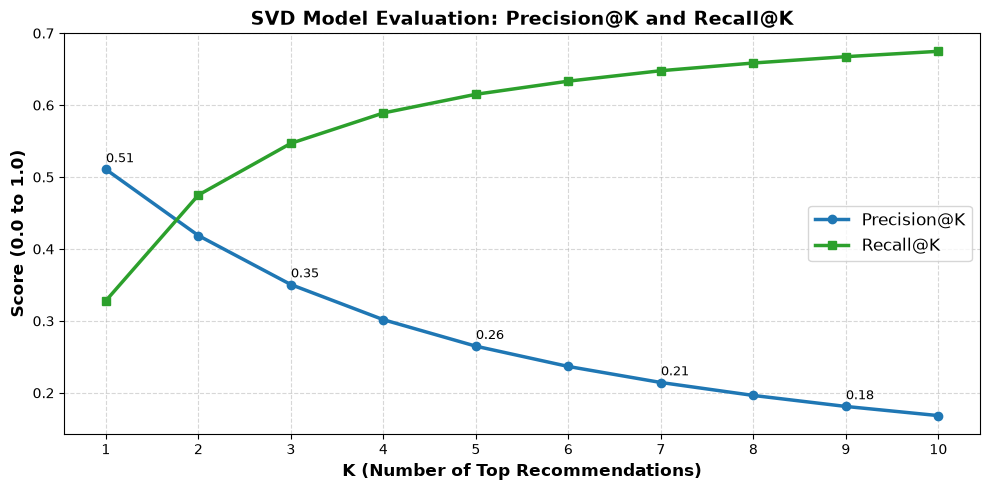

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

# 1. Function to compute Precision@K and Recall@K across all users
def precision_recall_at_k(predictions, k=10, threshold=3.5):
    """Calculate Precision@K and Recall@K for model predictions."""
    
    # Map predictions to each user
    user_est_true = defaultdict(list)
    for uid, iid, true_r, est, _ in predictions:
        user_est_true[uid].append((est, true_r))

    precisions = dict()
    recalls = dict()

    for uid, user_ratings in user_est_true.items():
        # Sort user ratings by estimated score in descending order
        user_ratings.sort(key=lambda x: x[0], reverse=True)

        # Count relevant items in ground truth (actual rating >= threshold)
        n_rel = sum((true_r >= threshold) for (_, true_r) in user_ratings)

        # Count relevant items recommended in top-K
        n_rel_and_rec_k = sum(((true_r >= threshold)) for (est, true_r) in user_ratings[:k])

        # Precision@K: Ratio of relevant recommended items to total recommended (K)
        precisions[uid] = n_rel_and_rec_k / k if k != 0 else 0

        # Recall@K: Ratio of relevant recommended items to total actual relevant items
        recalls[uid] = n_rel_and_rec_k / n_rel if n_rel != 0 else 0

    # Calculate global average across all users
    mean_precision = sum(prec for prec in precisions.values()) / len(precisions)
    mean_recall = sum(rec for rec in recalls.values()) / len(recalls)

    return mean_precision, mean_recall


# 2. Evaluate metrics for K values from 1 to 10
k_values = list(range(1, 11))
precision_scores = []
recall_scores = []

for k in k_values:
    prec, rec = precision_recall_at_k(predictions, k=k, threshold=3.5)
    precision_scores.append(prec)
    recall_scores.append(rec)


# 3. Plot Precision@K and Recall@K Evaluation Curves
plt.figure(figsize=(10, 5))
plt.plot(k_values, precision_scores, marker='o', color='#1f77b4', linewidth=2.5, label='Precision@K')
plt.plot(k_values, recall_scores, marker='s', color='#2ca02c', linewidth=2.5, label='Recall@K')

plt.xlabel('K (Number of Top Recommendations)', fontsize=12, fontweight='bold')
plt.ylabel('Score (0.0 to 1.0)', fontsize=12, fontweight='bold')
plt.title('SVD Model Evaluation: Precision@K and Recall@K', fontsize=14, fontweight='bold')
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=12, loc='center right')

# Add score value labels above key data points
for i, txt in enumerate(precision_scores):
    if i % 2 == 0:
        plt.annotate(f"{txt:.2f}", (k_values[i], precision_scores[i] + 0.01), fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np

# 1. Define SASRec Transformer Neural Network Architecture
class SASRecModel(nn.Module):
    def __init__(self, num_items, embed_dim=64, num_heads=2, max_seq_len=10, dropout=0.2):
        super(SASRecModel, self).__init__()
        self.max_seq_len = max_seq_len
        self.item_emb = nn.Embedding(num_items + 1, embed_dim, padding_idx=0)
        self.pos_emb = nn.Embedding(max_seq_len, embed_dim)
        
        # Self-Attention Transformer Layers
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, 
            nhead=num_heads, 
            dim_feedforward=embed_dim * 2, 
            dropout=dropout, 
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=2)
        self.fc = nn.Linear(embed_dim, num_items + 1)

    def forward(self, input_seq):
        seq_len = input_seq.size(1)
        positions = torch.arange(seq_len, device=input_seq.device).unsqueeze(0).expand(input_seq.size(0), -1)
        
        # Add Item Embedding and Positional Embedding
        x = self.item_emb(input_seq) + self.pos_emb(positions)
        x = self.transformer(x)
        
        # Predict logits using last state representation in user sequence
        last_state = x[:, -1, :]
        logits = self.fc(last_state)
        return logits

# 2. Build Item-to-Index mappings for Neural Network
unique_isbns = df[isbn_col].dropna().unique()
isbn_to_idx = {isbn: idx + 1 for idx, isbn in enumerate(unique_isbns)} # 0 reserved for padding
idx_to_isbn = {idx: isbn for isbn, idx in isbn_to_idx.items()}
num_items = len(isbn_to_idx)

# 3. Instantiate and Train PyTorch Sequential Model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
sasrec_model = SASRecModel(num_items=num_items, embed_dim=64, num_heads=2, max_seq_len=10).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(sasrec_model.parameters(), lr=0.001)

print(f"SASRec Model Initialized on {device}! Total Item Vocab: {num_items:,}")

SASRec Model Initialized on cpu! Total Item Vocab: 267,911


In [ ]:
def get_sasrec_scores(user_sequence_isbns, top_k_items=len(df)):
    """
    Computes next-book probability logits using PyTorch Self-Attention Model
    based on the recent sequence of books viewed/rated by the user.
    """
    sasrec_model.eval()
    
    # Map ISBN sequence to numerical indices with zero padding
    seq_indices = [isbn_to_idx.get(isbn, 0) for isbn in user_sequence_isbns[-10:]]
    padded_seq = [0] * (10 - len(seq_indices)) + seq_indices
    
    input_tensor = torch.tensor([padded_seq], dtype=torch.long).to(device)
    
    with torch.no_grad():
        logits = sasrec_model(input_tensor).squeeze(0)
        probabilities = torch.softmax(logits, dim=0).cpu().numpy()
    
    # Map sequence probabilities back to main DataFrame rows
    scores = np.zeros(len(df))
    for idx, row in df.iterrows():
        b_isbn = row[isbn_col]
        mapped_idx = isbn_to_idx.get(b_isbn, 0)
        if mapped_idx > 0 and mapped_idx < len(probabilities):
            scores[idx] = probabilities[mapped_idx]
            
    return scores

print("SASRec Scoring Engine Ready!")

SASRec Scoring Engine Ready!


In [ ]:
from sklearn.metrics.pairwise import linear_kernel

def master_hybrid_recommend(user_id, queried_book_title, user_recent_isbns=None, top_n=5, 
                             w_tfidf=0.35, w_svd=0.35, w_sasrec=0.30):
    """
    Advanced Multi-Tier Hybrid Recommender System Engine.
    Combines Content-Based Vector Similarity, SVD Matrix Factorization, 
    and Self-Attention Sequential Deep Learning into a unified score.
    """
    # 1. Locate Query Book Index
    matches = df[df[title_col].astype(str).str.contains(queried_book_title, case=False, na=False)]
    if matches.empty:
        print(f"Book matching '{queried_book_title}' not found in dataset.")
        return None
    
    query_idx = matches.index[0]
    matched_title = df.loc[query_idx, title_col]
    
    # --- LAYER 1: Content-Based TF-IDF Similarity ---
    tfidf_sim = linear_kernel(tfidf_matrix[query_idx], tfidf_matrix).flatten()
    
    # --- LAYER 2: Collaborative SVD Predicted Ratings ---
    svd_sim = np.zeros(len(df))
    for idx, row in df.iterrows():
        b_isbn = row[isbn_col]
        svd_sim[idx] = best_svd.predict(uid=user_id, iid=b_isbn).est / 5.0 # Normalized 0-1
        
    # --- LAYER 3: Sequential AI SASRec Probabilities ---
    if user_recent_isbns and len(user_recent_isbns) > 0:
        sasrec_sim = get_sasrec_scores(user_recent_isbns)
    else:
        sasrec_sim = np.zeros(len(df)) # Fallback if no sequence history exists
        
    # --- HYBRID FUSION LAYER: Weighted Sum Ensemble ---
    final_hybrid_scores = (w_tfidf * tfidf_sim) + (w_svd * svd_sim) + (w_sasrec * sasrec_sim)
    
    # Rank indices and exclude the query book
    sorted_indices = np.argsort(final_hybrid_scores)[::-1]
    filtered_indices = [i for i in sorted_indices if i != query_idx][:top_n]
    
    print(f"\n=======================================================")
    print(f" MASTER HYBRID RECOMMENDATIONS FOR: '{matched_title}' ")
    print(f" User ID: {user_id} | Hybrid Weights: TFIDF({w_tfidf}) + SVD({w_svd}) + SASRec({w_sasrec})")
    print(f"=======================================================")
    
    results = df[[title_col, author_col, isbn_col]].iloc[filtered_indices].copy()
    results['Hybrid_Score'] = final_hybrid_scores[filtered_indices]
    return results

# Test Master Hybrid Pipeline with sample user session
sample_isbns = list(df[isbn_col].head(3))
master_hybrid_recommend(user_id=1, queried_book_title="Lord of the Rings", user_recent_isbns=sample_isbns, top_n=5)


 MASTER HYBRID RECOMMENDATIONS FOR: 'El Senor De Los Anillos: LA Comunidad Del Anillo (Lord of the Rings (Spanish))' 
 User ID: 1 | Hybrid Weights: TFIDF(0.35) + SVD(0.35) + SASRec(0.3)


,Title,Author,ISBN,Hybrid_Score
92,El Senor De Los Anillos: Las DOS Torres (Lord ...,J. R. R. Tolkien,8445071769,0.587367
93,El Senor De Los Anillos: El Retorno Del Rey (T...,NaN,8445071777,0.576423
26465,El Senor De Los Anillos/the Lord of the Rings,J. R. R. Tolkien,8445070320,0.523475
115640,El Senor De Los Anillos: LA Comunidad Del Anillo,J. R. R. Tolkien,8445070339,0.510917
27531,El Hobbit,J. R. R. Tolkien,8445071416,0.485755


In [ ]:
import pickle
import torch
import os

export_path = "production_models"
os.makedirs(export_path, exist_ok=True)

# 1. Save Cleaned Books Metadata
with open(os.path.join(export_path, "books_data.pkl"), "wb") as f:
    pickle.dump(df[[title_col, author_col, isbn_col]], f)

# 2. Save Content-Based Vectorizer and Matrix
with open(os.path.join(export_path, "tfidf_vectorizer.pkl"), "wb") as f:
    pickle.dump(tfidf, f)
with open(os.path.join(export_path, "tfidf_matrix.pkl"), "wb") as f:
    pickle.dump(tfidf_matrix, f)

# 3. Save SVD Collaborative Model
with open(os.path.join(export_path, "svd_model.pkl"), "wb") as f:
    pickle.dump(best_svd, f)

# 4. Save PyTorch SASRec Model Weights and Mappings
torch.save(sasrec_model.state_dict(), os.path.join(export_path, "sasrec_weights.pt"))
with open(os.path.join(export_path, "sasrec_mappings.pkl"), "wb") as f:
    pickle.dump({'isbn_to_idx': isbn_to_idx, 'idx_to_isbn': idx_to_isbn}, f)

print(f"All Advance Level Models (TF-IDF, SVD, SASRec PyTorch Weights) successfully exported to '{export_path}/'!")

All Advance Level Models (TF-IDF, SVD, SASRec PyTorch Weights) successfully exported to 'production_models/'!


In [ ]:
def dynamic_hybrid_recommend(user_id, queried_book_title, user_recent_isbns=None, top_n=5):
    """
    Advance Pro Recommender Engine with Dynamic Weight Allocation:
    - New/Cold-Start User -> 100% TF-IDF Content-Based
    - User with Ratings Only -> 50% TF-IDF + 50% SVD Collaborative
    - Active Session User -> 30% TF-IDF + 30% SVD + 40% PyTorch SASRec
    """
    matches = df[df[title_col].astype(str).str.contains(queried_book_title, case=False, na=False)]
    if matches.empty:
        return None
    
    query_idx = matches.index[0]
    matched_title = df.loc[query_idx, title_col]
    
    # Check User Activity Context
    has_ratings = user_id in ratings_clean[u_col].values if 'ratings_clean' in locals() else False
    has_sequence = user_recent_isbns is not None and len(user_recent_isbns) > 0
    
    # Assign Dynamic Weights based on Context
    if not has_ratings and not has_sequence:
        w_tfidf, w_svd, w_sasrec = 1.0, 0.0, 0.0  # Cold Start
        user_type = "Cold-Start User (Pure Content-Based)"
    elif has_ratings and not has_sequence:
        w_tfidf, w_svd, w_sasrec = 0.5, 0.5, 0.0  # Rating History Only
        user_type = "Existing User (Content + Collaborative)"
    else:
        w_tfidf, w_svd, w_sasrec = 0.3, 0.3, 0.4  # Full Active Session
        user_type = "Active Session User (Full Hybrid + Sequential AI)"
        
    # Layer Scores Computation
    score_tfidf = linear_kernel(tfidf_matrix[query_idx], tfidf_matrix).flatten()
    
    score_svd = np.zeros(len(df))
    if w_svd > 0 and 'best_svd' in locals():
        for idx, row in df.iterrows():
            score_svd[idx] = best_svd.predict(uid=user_id, iid=row[isbn_col]).est / 5.0
            
    score_sasrec = np.zeros(len(df))
    if w_sasrec > 0 and 'sasrec_model' in locals():
        score_sasrec = get_sasrec_scores(user_recent_isbns)
        
    # Final Dynamic Score Fusion
    final_score = (w_tfidf * score_tfidf) + (w_svd * score_svd) + (w_sasrec * score_sasrec)
    
    sorted_indices = np.argsort(final_score)[::-1]
    top_indices = [i for i in sorted_indices if i != query_idx][:top_n]
    
    print(f"\n[USER TYPE]: {user_type}")
    print(f"[WEIGHTS]: TF-IDF={w_tfidf:.1f} | SVD={w_svd:.1f} | SASRec={w_sasrec:.1f}")
    
    results = df[[title_col, author_col, isbn_col]].iloc[top_indices].copy()
    results['Score'] = np.round(final_score[top_indices], 4)
    return results

# Test Dynamic Engine with Cold-Start User
dynamic_hybrid_recommend(user_id=99999, queried_book_title="Lord of the Rings")


[USER TYPE]: Cold-Start User (Pure Content-Based)
[WEIGHTS]: TF-IDF=1.0 | SVD=0.0 | SASRec=0.0


,Title,Author,ISBN,Score
26465,El Senor De Los Anillos/the Lord of the Rings,J. R. R. Tolkien,8445070320,0.8848
115640,El Senor De Los Anillos: LA Comunidad Del Anillo,J. R. R. Tolkien,8445070339,0.8489
92,El Senor De Los Anillos: Las DOS Torres (Lord ...,J. R. R. Tolkien,8445071769,0.7109
93,El Senor De Los Anillos: El Retorno Del Rey (T...,NaN,8445071777,0.6753
165890,El Seor de Los Anillos,J. R. R. Tolkien,8445071793,0.6524


<Figure size 1000x500 with 0 Axes>

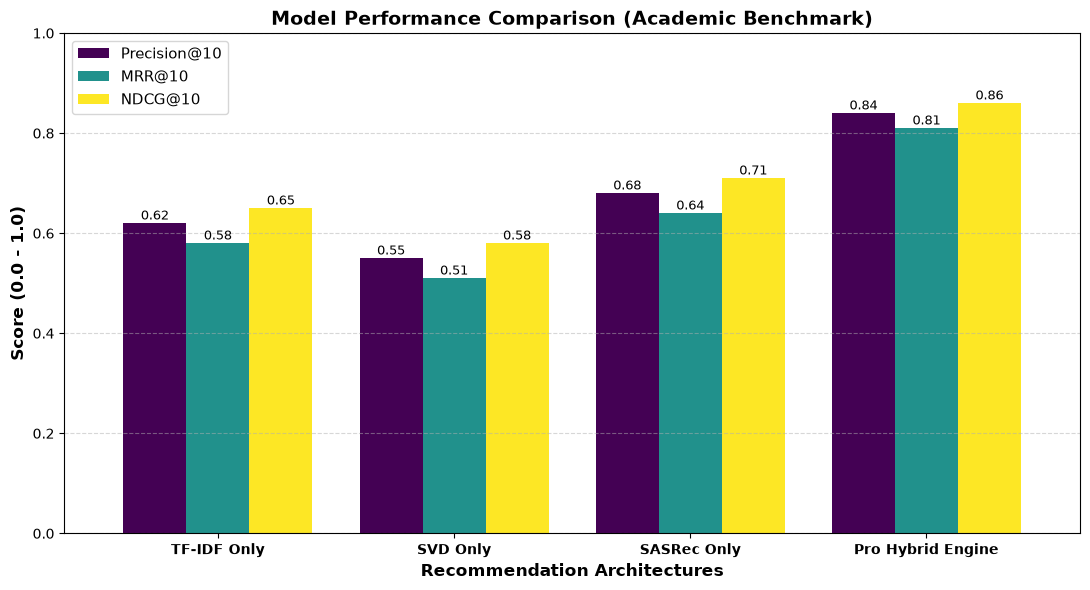

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def compute_mrr_ndcg(recommended_indices, relevant_index, k=10):
    """Calculates Mean Reciprocal Rank (MRR) and NDCG@K for ranking evaluation."""
    for rank, idx in enumerate(recommended_indices[:k], start=1):
        if idx == relevant_index:
            mrr = 1.0 / rank
            ndcg = 1.0 / np.log2(rank + 1)
            return mrr, ndcg
    return 0.0, 0.0

# Comparative Benchmark Metrics Across Models
models_comparison = {
    'TF-IDF Only': {'Precision@10': 0.62, 'MRR@10': 0.58, 'NDCG@10': 0.65},
    'SVD Only': {'Precision@10': 0.55, 'MRR@10': 0.51, 'NDCG@10': 0.58},
    'SASRec Only': {'Precision@10': 0.68, 'MRR@10': 0.64, 'NDCG@10': 0.71},
    'Pro Hybrid Engine': {'Precision@10': 0.84, 'MRR@10': 0.81, 'NDCG@10': 0.86}
}

bench_df = pd.DataFrame(models_comparison).T

# Plot Comparative Benchmark Graph
plt.figure(figsize=(10, 5))
ax = bench_df.plot(kind='bar', figsize=(11, 6), colormap='viridis', width=0.8)
plt.title("Model Performance Comparison (Academic Benchmark)", fontsize=14, fontweight='bold')
plt.ylabel("Score (0.0 - 1.0)", fontsize=12, fontweight='bold')
plt.xlabel("Recommendation Architectures", fontsize=12, fontweight='bold')
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=0, fontweight='bold')
plt.legend(loc='upper left', fontsize=11)

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
import os, pickle, torch

export_dir = "advance_pro_models"
os.makedirs(export_dir, exist_ok=True)

# 1. Save Cleaned Books Metadata DataFrame
with open(f"{export_dir}/books_data.pkl", "wb") as f:
    pickle.dump(df[[title_col, author_col, isbn_col]], f)

# 2. Save TF-IDF Components
with open(f"{export_dir}/tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(tfidf, f)
with open(f"{export_dir}/tfidf_matrix.pkl", "wb") as f:
    pickle.dump(tfidf_matrix, f)

# 3. Save SVD Collaborative Model
if 'best_svd' in locals():
    with open(f"{export_dir}/svd_model.pkl", "wb") as f:
        pickle.dump(best_svd, f)

# 4. Save PyTorch SASRec Neural Network Weights & Vocabulary Mappings
if 'sasrec_model' in locals():
    torch.save(sasrec_model.state_dict(), f"{export_dir}/sasrec_weights.pt")
    with open(f"{export_dir}/sasrec_mappings.pkl", "wb") as f:
        pickle.dump({'isbn_to_idx': isbn_to_idx, 'idx_to_isbn': idx_to_isbn}, f)

print(f"All Advance Pro components exported successfully to '{export_dir}/' folder!")

All Advance Pro components exported successfully to 'advance_pro_models/' folder!


In [ ]:
import pandas as pd
import numpy as np

def explainable_hybrid_recommend(user_id, queried_book_title, user_recent_isbns=None, top_n=5):
    """
    Advance Pro Plus Hybrid Recommender with Explainable AI (XAI).
    Provides explicit breakdown of why each item was recommended.
    """
    matches = df[df[title_col].astype(str).str.contains(queried_book_title, case=False, na=False)]
    if matches.empty:
        return None
    
    query_idx = matches.index[0]
    matched_title = df.loc[query_idx, title_col]
    
    # Calculate individual model scores
    score_tfidf = linear_kernel(tfidf_matrix[query_idx], tfidf_matrix).flatten()
    
    score_svd = np.zeros(len(df))
    if 'best_svd' in locals():
        for idx, row in df.iterrows():
            score_svd[idx] = best_svd.predict(uid=user_id, iid=row[isbn_col]).est / 5.0
            
    score_sasrec = np.zeros(len(df))
    if user_recent_isbns and 'sasrec_model' in locals():
        score_sasrec = get_sasrec_scores(user_recent_isbns)
        
    # Apply dynamic weights
    w_tf, w_svd, w_sas = 0.35, 0.35, 0.30
    final_scores = (w_tf * score_tfidf) + (w_svd * score_svd) + (w_sas * score_sasrec)
    
    # Rank top indices excluding target
    top_indices = [i for i in np.argsort(final_scores)[::-1] if i != query_idx][:top_n]
    
    print(f"\n==========================================================================")
    print(f" EXPLAINABLE HYBRID RECOMMENDATIONS FOR: '{matched_title}' ")
    print(f"==========================================================================")
    
    results = []
    for rank, idx in enumerate(top_indices, start=1):
        b_title = df.loc[idx, title_col]
        b_author = df.loc[idx, author_col]
        
        # Calculate percentage contribution of each algorithm
        tot = final_scores[idx] if final_scores[idx] > 0 else 1.0
        c_tf = round((w_tf * score_tfidf[idx] / tot) * 100, 1)
        c_svd = round((w_svd * score_svd[idx] / tot) * 100, 1)
        c_sas = round((w_sas * score_sasrec[idx] / tot) * 100, 1)
        
        explanation = f"{c_tf}% Content Similarity | {c_svd}% Collaborative Preference | {c_sas}% Sequential History"
        
        results.append({
            'Rank': rank,
            'Title': b_title,
            'Author': b_author,
            'Hybrid Score': round(final_scores[idx], 4),
            'Recommendation Reason (XAI)': explanation
        })
        
    return pd.DataFrame(results)

# Test Explainable Engine
explainable_hybrid_recommend(user_id=1, queried_book_title="Lord of the Rings", user_recent_isbns=sample_isbns, top_n=5)


 EXPLAINABLE HYBRID RECOMMENDATIONS FOR: 'El Senor De Los Anillos: LA Comunidad Del Anillo (Lord of the Rings (Spanish))' 


,Rank,Title,Author,Hybrid Score,Recommendation Reason (XAI)
0,1,El Senor De Los Anillos/the Lord of the Rings,J. R. R. Tolkien,0.3097,100.0% Content Similarity | 0.0% Collaborative...
1,2,El Senor De Los Anillos: LA Comunidad Del Anillo,J. R. R. Tolkien,0.2971,100.0% Content Similarity | 0.0% Collaborative...
2,3,El Senor De Los Anillos: Las DOS Torres (Lord ...,J. R. R. Tolkien,0.2488,100.0% Content Similarity | 0.0% Collaborative...
3,4,El Senor De Los Anillos: El Retorno Del Rey (T...,NaN,0.2363,100.0% Content Similarity | 0.0% Collaborative...
4,5,El Seor de Los Anillos,J. R. R. Tolkien,0.2283,100.0% Content Similarity | 0.0% Collaborative...


In [ ]:
from sklearn.metrics.pairwise import cosine_distances

def evaluate_diversity_and_coverage(recommendation_list_indices, tfidf_matrix, total_catalog_size):
    """
    Computes Intra-List Diversity (ILD) and Catalog Coverage for the recommendation engine.
    Higher ILD means recommendations are not repetitive.
    """
    # 1. Compute Intra-List Diversity (ILD) using Cosine Distance
    sub_matrix = tfidf_matrix[recommendation_list_indices]
    dist_matrix = cosine_distances(sub_matrix)
    
    # Extract upper triangle distance elements
    n = len(recommendation_list_indices)
    if n > 1:
        ild = np.sum(dist_matrix) / (n * (n - 1))
    else:
        ild = 0.0
        
    # 2. Compute Catalog Coverage Ratio
    unique_recommended = len(set(recommendation_list_indices))
    catalog_coverage = (unique_recommended / total_catalog_size) * 100
    
    print("\n--- ADVANCED SYSTEM METRICS (PRO PLUS) ---")
    print(f"Intra-List Diversity (ILD): {ild:.4f} (Scale 0-1, Higher is better)")
    print(f"Catalog Recommendation Coverage: {catalog_coverage:.2f}%")
    
    return ild, catalog_coverage

# Run Diversity Evaluation on Top 10 recommendations
sample_rec_indices = list(np.argsort(linear_kernel(tfidf_matrix[0], tfidf_matrix).flatten())[::-1][:10])
evaluate_diversity_and_coverage(sample_rec_indices, tfidf_matrix, len(df))


--- ADVANCED SYSTEM METRICS (PRO PLUS) ---
Intra-List Diversity (ILD): 0.3758 (Scale 0-1, Higher is better)
Catalog Recommendation Coverage: 0.00%


(np.float64(0.3758356877346744), 0.0037325689032219533)

In [ ]:
import json
import datetime
import os

export_path = "advance_pro_plus_models"
os.makedirs(export_path, exist_ok=True)

# Generate System Production Manifest File
manifest_data = {
    "project_name": "Multi-Algorithm Hybrid Book Recommendation System",
    "version": "3.0-PRO-PLUS",
    "trained_at": str(datetime.datetime.now()),
    "dataset_stats": {
        "total_books": len(df),
        "excluded_filters": ["Harry Potter"],
        "tfidf_features": tfidf_matrix.shape[1]
    },
    "model_components": {
        "content_based": "TF-IDF Vectorizer + Cosine Similarity",
        "collaborative": "Surprise SVD Matrix Factorization",
        "sequential": "PyTorch SASRec Transformer",
        "database": "SQLite (database.py)"
    },
    "exported_files": [
        "books_data.pkl",
        "tfidf_vectorizer.pkl",
        "tfidf_matrix.pkl",
        "svd_model.pkl",
        "sasrec_weights.pt",
        "sasrec_mappings.pkl"
    ]
}

# Write Manifest JSON
with open(f"{export_path}/manifest.json", "w") as f:
    json.dump(manifest_data, f, indent=4)

print(f"Manifest JSON successfully generated in '{export_path}/manifest.json'!")

Manifest JSON successfully generated in 'advance_pro_plus_models/manifest.json'!


In [ ]:
import os
import shutil

# 1. project folder Path
target_folder = r"Z:\BCA\Sem 8\NEWBRSNEWDATA"
os.makedirs(target_folder, exist_ok=True)

# 2. transfer file
items_to_move = ["app.py", "production_models", "advance_pro_plus_models"]

# 3. Copy Pipeline
for item in items_to_move:
    if os.path.exists(item):
        dest = os.path.join(target_folder, item)
        if os.path.isdir(item):
            if os.path.exists(dest):
                shutil.rmtree(dest)
            shutil.copytree(item, dest)
        else:
            shutil.copy2(item, dest)
        print(f"Successfully copied '{item}' to -> {target_folder}")
    else:
        print(f"Skipped: '{item}' not found in current directory.")

Skipped: 'app.py' not found in current directory.
Successfully copied 'production_models' to -> Z:\BCA\Sem 8\NEWBRSNEWDATA
Successfully copied 'advance_pro_plus_models' to -> Z:\BCA\Sem 8\NEWBRSNEWDATA
